# Day 5 Hands-On Challenge: Dashboard Components
Assumptions: sales = `net_sales`; Cancelled and Returned orders excluded; order value = total `net_sales` per `order_id`.

In [1]:
# Run once if needed:
# !pip install pandas matplotlib plotly streamlit

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "_sales_analysis_day5.csv"
EXCLUDED_STATUSES = ["Cancelled", "Returned"]

## Helper functions (reusable in Streamlit on Day 6)

In [3]:
def load_data(path=CSV_PATH):
    df = pd.read_csv(path, parse_dates=["order_date"])
    return df[~df["order_status"].isin(EXCLUDED_STATUSES)].copy()


def order_values(df):
    """One row per order with its total value (for histogram/box plot)."""
    return df.groupby("order_id", as_index=False)["net_sales"].sum()

In [4]:
# KPIs
def compute_kpis(df):
    total_sales = df["net_sales"].sum()
    orders = df["order_id"].nunique()
    aov = total_sales / orders
    by_cat = df.groupby("category_clean")["net_sales"].sum().sort_values(ascending=False)
    return {
        "Total Sales": total_sales,
        "Orders": orders,
        "AOV": aov,
        "Top Category": by_cat.index[0],
        "Top Category Sales": by_cat.iloc[0],
    }

In [5]:
# Charts

def bar_sales_by_category(df):
    s = df.groupby("category_clean")["net_sales"].sum().sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(s.index, s.values, color="#1f77b4")
    ax.set_title("Net Sales by Category")
    ax.set_xlabel("Net Sales")
    ax.set_ylabel("Category")
    fig.tight_layout()
    return fig, s


def line_monthly_sales(df):
    s = df.groupby("month")["net_sales"].sum().sort_index()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(s.index, s.values, marker="o", color="#1f77b4")
    ax.set_title("Monthly Net Sales")
    ax.set_xlabel("Month")
    ax.set_ylabel("Net Sales")
    ax.tick_params(axis="x", rotation=60)
    fig.tight_layout()
    return fig, s


def hist_order_value(df):
    ov = order_values(df)["net_sales"]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(ov, bins=40, color="#1f77b4", edgecolor="white")
    ax.axvline(ov.median(), color="red", linestyle="--", label=f"Median: {ov.median():,.0f}")
    ax.set_title("Distribution of Order Value")
    ax.set_xlabel("Order Value (net sales per order)")
    ax.set_ylabel("Number of Orders")
    ax.legend()
    fig.tight_layout()
    return fig, ov

In [6]:
# Plotly + interpretations

def plotly_bar_sales_by_category(df):
    import plotly.express as px

    s = (
        df.groupby("category_clean", as_index=False)["net_sales"]
        .sum()
        .sort_values("net_sales")
    )
    fig = px.bar(
        s,
        x="net_sales",
        y="category_clean",
        orientation="h",
        title="Net Sales by Category (hover for exact values)",
        labels={"net_sales": "Net Sales", "category_clean": "Category"},
        hover_data={"net_sales": ":,.2f"},
    )
    return fig


# ---------------------------------------------------------------- interpretations (task 6)
def interpret_bar(s):
    top, low = s.index[-1], s.index[0]
    share = s.iloc[-1] / s.sum() * 100
    return (f"{top} is the top category with {share:.1f}% of total sales, "
            f"while {low} is the lowest.")


def interpret_line(s):
    peak, trough = s.idxmax(), s.idxmin()
    return (f"Monthly sales fluctuate with no clear long-term trend, peaking in {peak} "
            f"({s.max():,.0f}) and dipping lowest in {trough} ({s.min():,.0f}).")


def interpret_hist(ov):
    return (f"Most orders are small: the median order is {ov.median():,.0f} but the average "
            f"is {ov.mean():,.0f}, because a few large orders stretch the right tail.")


def interpret_plotly(s):
    return interpret_bar(s)

## Load data

In [7]:
df = load_data()
df.shape

(30544, 27)

## Task 5: KPIs

In [8]:
k = compute_kpis(df)
print(f"Total Sales : {k['Total Sales']:,.2f}")
print(f"Orders      : {k['Orders']:,}")
print(f"AOV         : {k['AOV']:,.2f}")
print(f"Top Category: {k['Top Category']} ({k['Top Category Sales']:,.2f})")

Total Sales : 5,598,085.23
Orders      : 12,936
AOV         : 432.75
Top Category: Toys (777,792.00)


## Task 1: Bar chart, sales by category

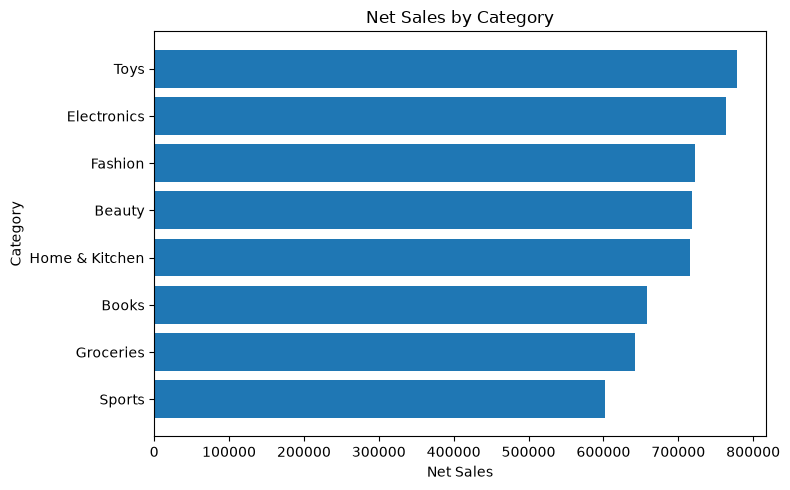

Toys is the top category with 13.9% of total sales, while Sports is the lowest.


In [9]:
fig1, s_cat = bar_sales_by_category(df)
plt.show()
print(interpret_bar(s_cat))

## Task 2: Line chart, monthly sales

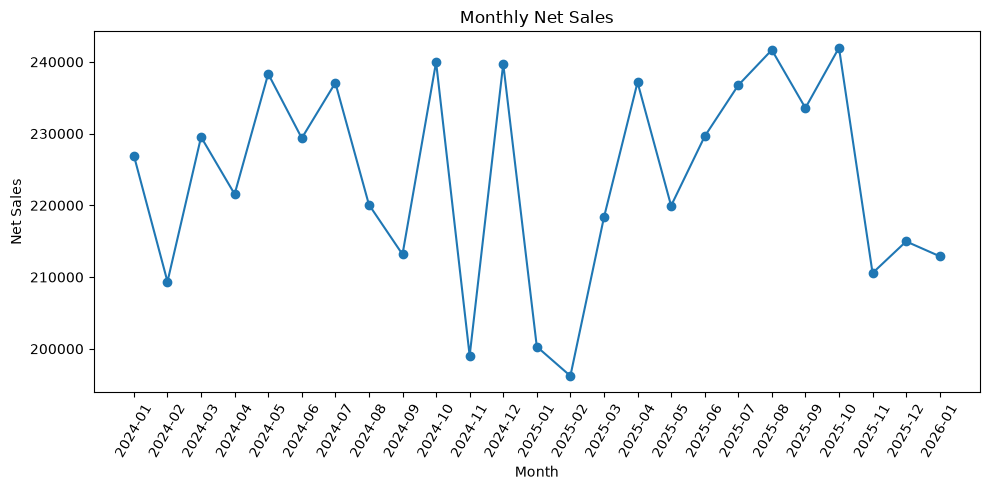

Monthly sales fluctuate with no clear long-term trend, peaking in 2025-10 (241,970) and dipping lowest in 2025-02 (196,218).


In [10]:
fig2, s_month = line_monthly_sales(df)
plt.show()
print(interpret_line(s_month))

## Task 3: Histogram, order value

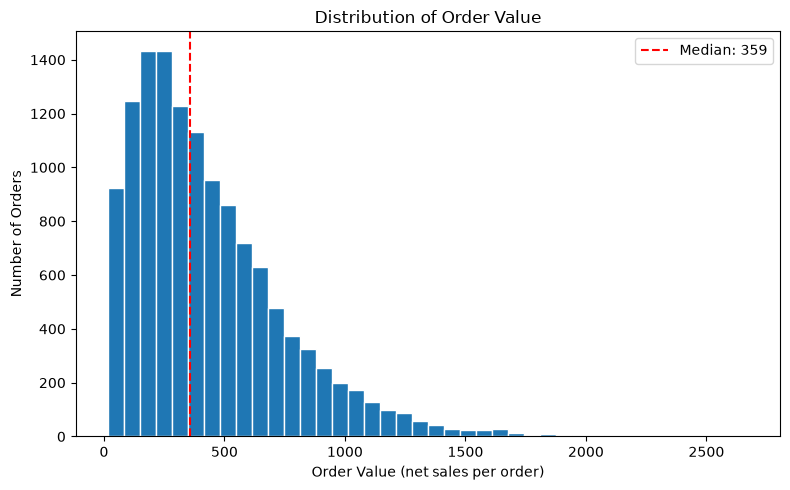

Most orders are small: the median order is 359 but the average is 433, because a few large orders stretch the right tail.


In [11]:
fig3, ov = hist_order_value(df)
plt.show()
print(interpret_hist(ov))

## Task 4: Plotly chart (hover over the bars)

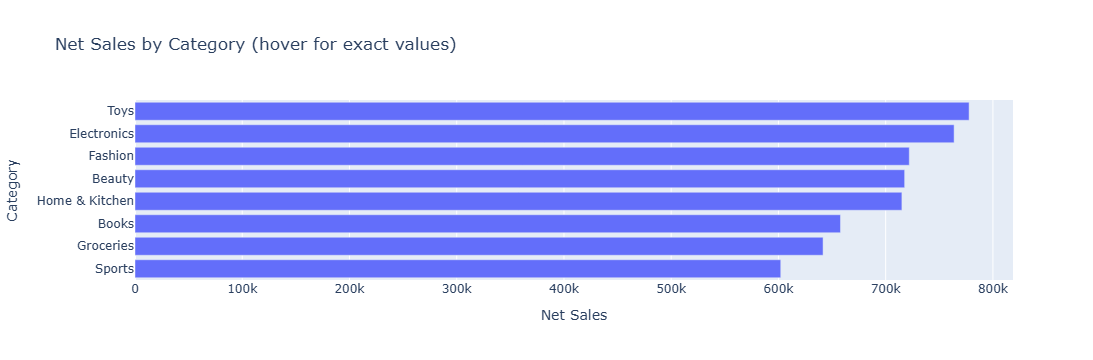

Toys is the top category with 13.9% of total sales, while Sports is the lowest.


In [12]:
pfig = plotly_bar_sales_by_category(df)
pfig.show()
print(interpret_plotly(s_cat))